In [1]:
library(dplyr)
library(Seurat)
library(ggplot2)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


v5.6 adds significant improvements in speed and efficiency, particularly for large datasets.
For more information, see https://satijalab.org/seurat/articles/announcements.




In [3]:
postchemo <- readRDS('../Results/PostChemo/postchemo_annotated.rds')

In [5]:
colnames(postchemo@meta.data)

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "sample_id"              "percent.mt"             "percent.eryth"         
 [7] "treatment"              "integrated_snn_res.0.3" "seurat_clusters"       
[10] "cell_type"

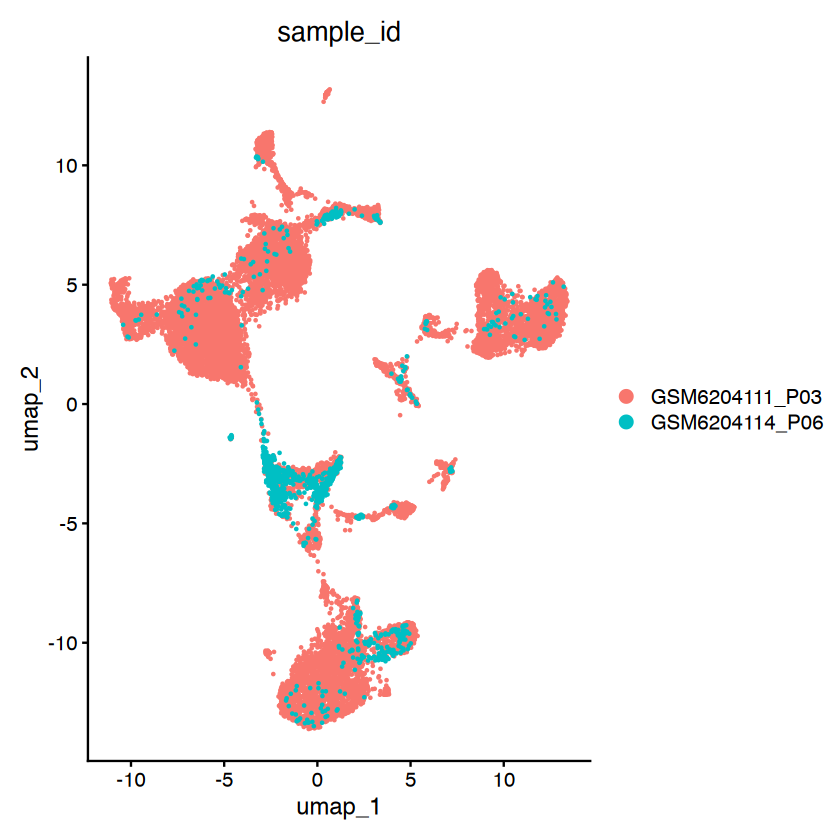

In [6]:
DimPlot(postchemo, group.by = 'sample_id')

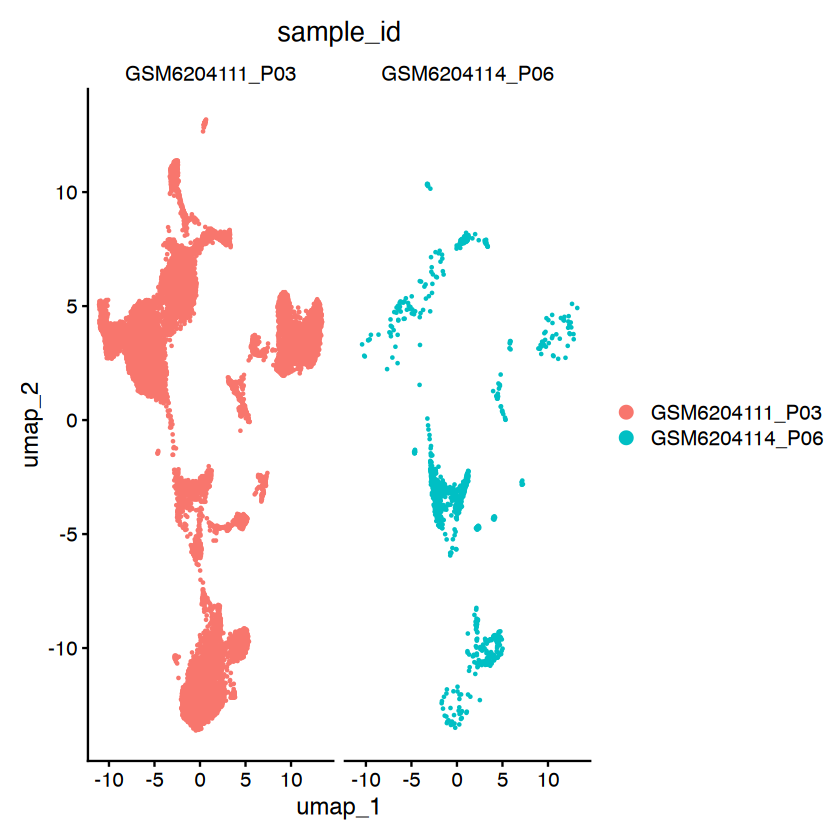

In [7]:
DimPlot(postchemo, group.by = 'sample_id', split.by='sample_id')

In [8]:
cell_type_markers <- list(
  "T/NK" = c("CCL5", "GNLY", "NKG7", "CCL4", "IL7R"),

  "Epithelial" = c("TFF1", "LCN2", "KRT19", "SPINK1", "TFF2"),

  "Endothelial" = c("SPARCL1", "ACKR1", "CCL14", "VWF", "COL4A1"),

  "Myeloid" = c("SPP1", "APOE", "S100A9", "IFI30", "HLA-DRA"),

  "Prolif. epithelial" = c("UBE2C", "AKR1C2", "UBE2S", "CCNB1", "S100A2"),

  "Prolif. lymphoid" = c("HIST1H4C", "HMGB2", "STMN1", "MKI67", "CENPF"),

  "B/Plasma" = c("IGKC", "IGLC2", "IGHG1", "IGLC3", "IGLC1"),

  "Prolif. myeloid" = c("MMP9", "CTSK", "ACP5", "CST3", "RGS10"),

  "CAFs" = c("COL3A1", "COL1A2", "COL1A1", "SFRP2", "DCN"),

  "Mast" = c("TPSAB1", "TPSB2", "CPA3", "MS4A2", "KIT")
)

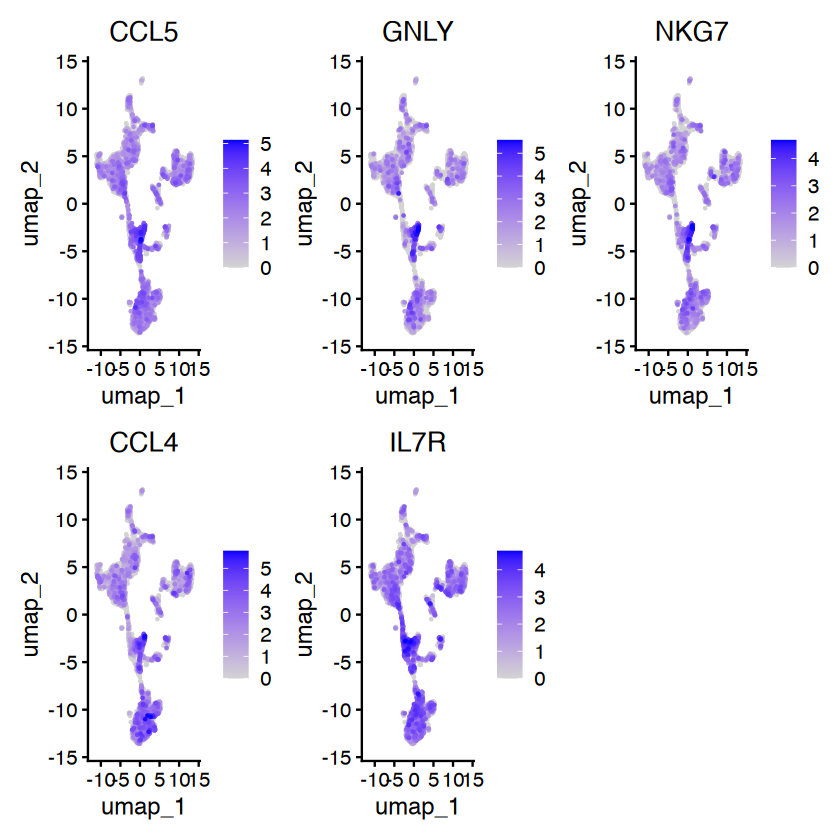

In [9]:
DefaultAssay(postchemo) <- "RNA"

FeaturePlot(
  object = postchemo,
  features = cell_type_markers[["T/NK"]],
  reduction = "umap",
  ncol = 3,
  order = TRUE
)

Warning message in DoHeatmap(object = postchemo, features = markers, assay = "RNA", :
“The following features were omitted as they were not found in the scale.data layer for the RNA assay: KIT, DCN, COL1A1, COL1A2, COL3A1, RGS10, CST3, ACP5, CTSK, IGLC3, IGHG1, CENPF, MKI67, STMN1, HMGB2, HIST1H4C, S100A2, UBE2S, AKR1C2, UBE2C, HLA-DRA, IFI30, APOE, SPP1, COL4A1, VWF, SPARCL1, TFF2, SPINK1, KRT19, LCN2, TFF1, IL7R, CCL4, NKG7, GNLY, CCL5”
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


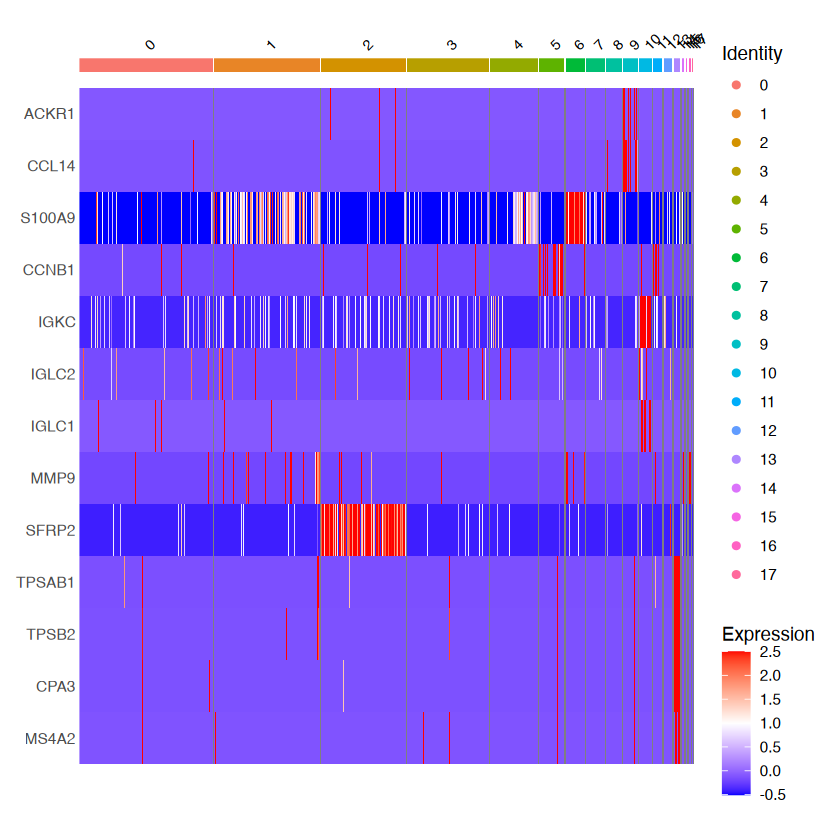

In [10]:
DefaultAssay(postchemo) <- "RNA"

markers <- unlist(cell_type_markers, use.names = FALSE)

# Keep available genes
markers <- markers[markers %in% rownames(postchemo)]

# Plot heatmap
DoHeatmap(
  object = postchemo,
  features = markers,
  assay = "RNA",
  slot = "scale.data",
  group.by = NULL,
  disp.min = -2.5,
  disp.max = 2.5,
  size = 3,
  raster = TRUE
) +
  scale_fill_gradientn(
    colors = c("blue", "white", "red")
  ) +
  theme(
    axis.text.x = element_blank(),
    axis.text.y = element_text(size = 9)
  )



In [11]:
options(repr.plot.width = 20, repr.plot.height = 7)

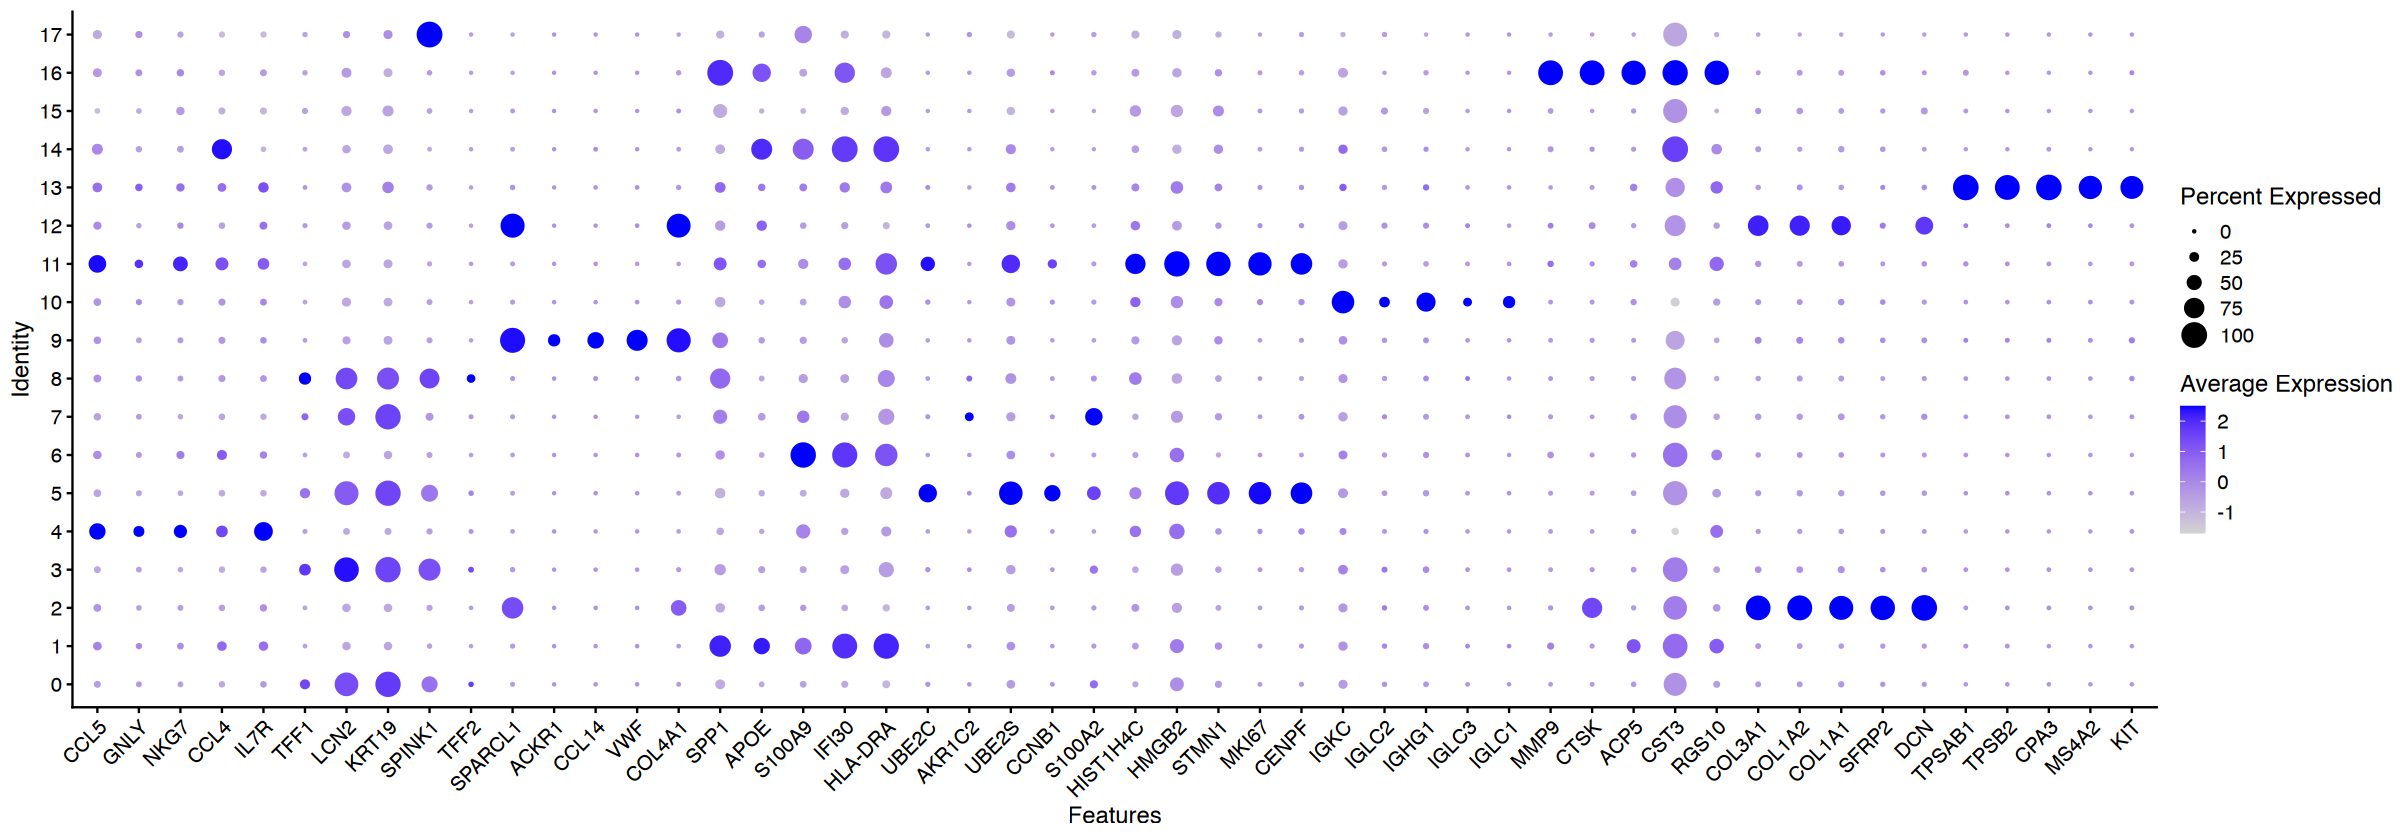

In [13]:
DotPlot(postchemo, features = markers) + RotatedAxis()

Warning message:
“Scaling data with a low number of groups may produce misleading results”


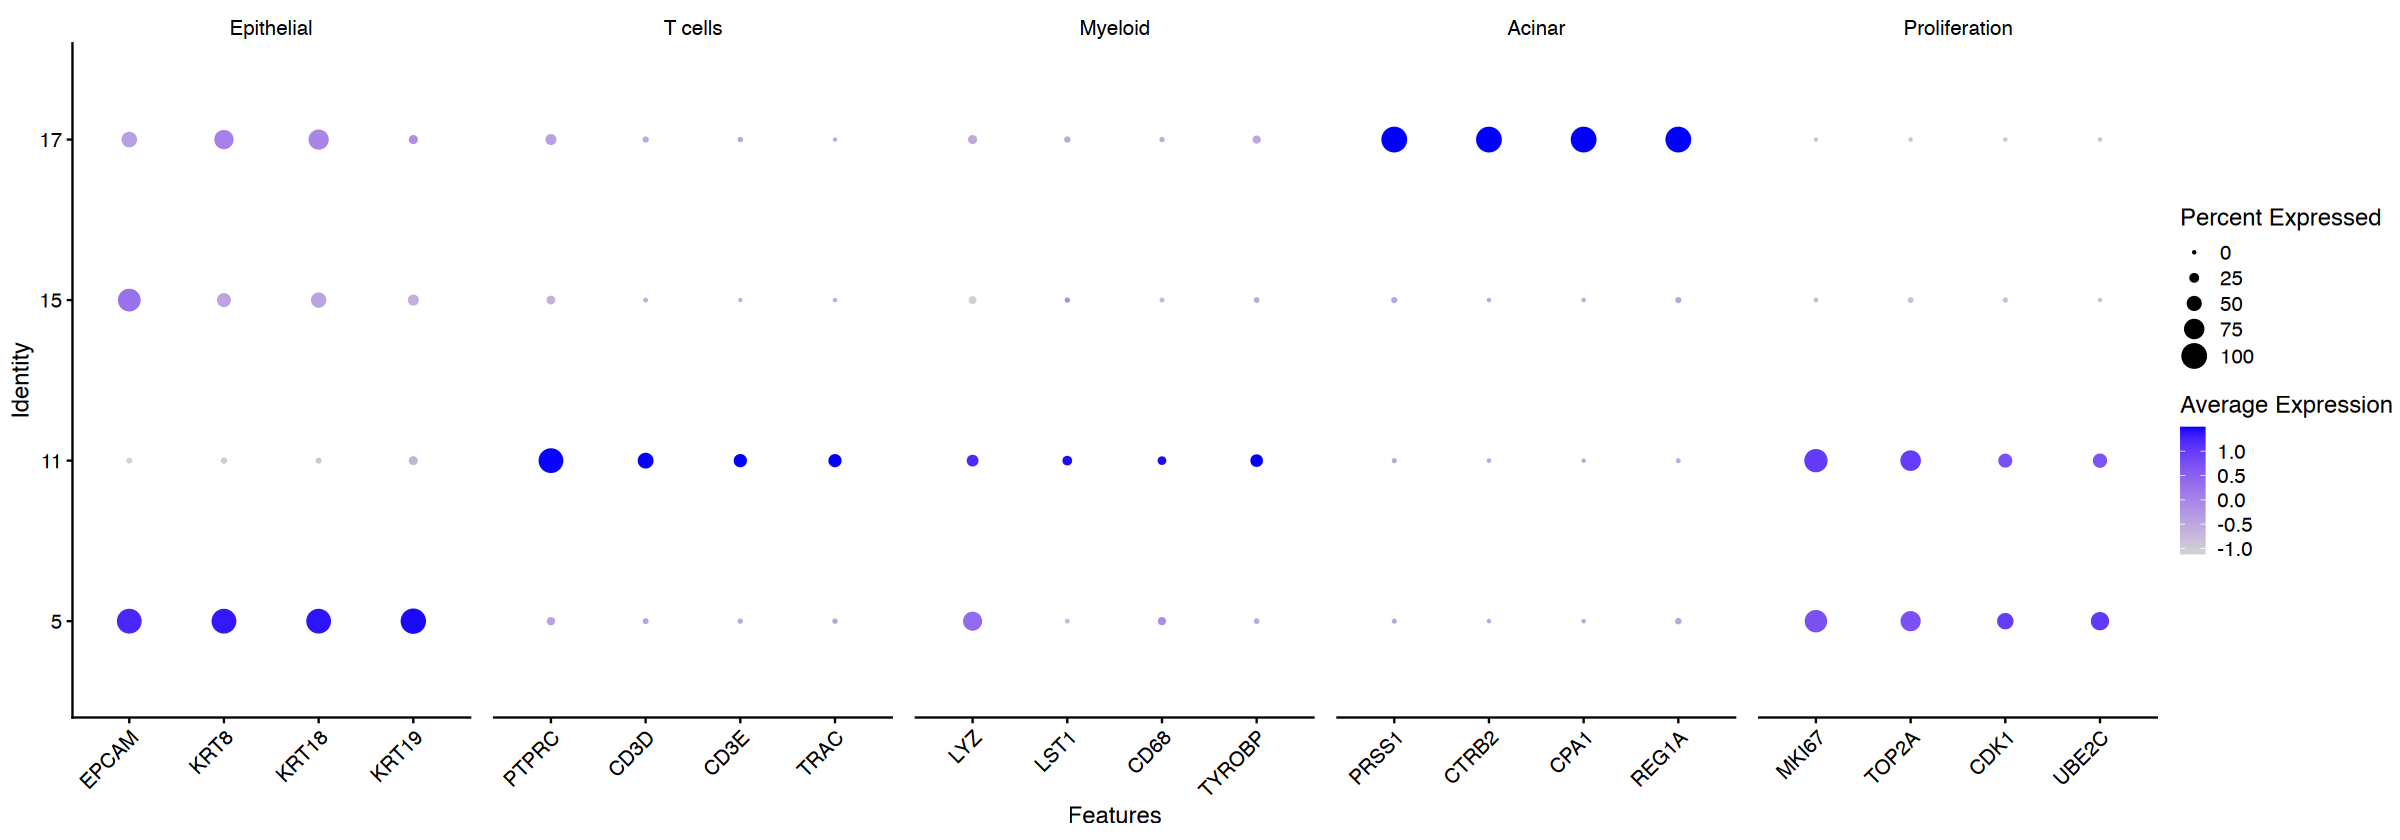

In [17]:
DotPlot(
  subset(postchemo, idents = c(5, 11, 15, 17)),
  features = list(
    "Epithelial" = c("EPCAM", "KRT8", "KRT18", "KRT19"),
    "T cells" = c("PTPRC", "CD3D", "CD3E", "TRAC"),
    "Myeloid" = c("LYZ", "LST1", "CD68", "TYROBP"),
    "Acinar" = c("PRSS1", "CTRB2", "CPA1", "REG1A"),
    "Proliferation" = c("MKI67", "TOP2A", "CDK1", "UBE2C")
  )
) + RotatedAxis()

In [19]:
postchemo_annotations <- c(
  "0"  = "Epithelial",
  "1"  = "Myeloid",
  "2"  = "CAFs",
  "3"  = "Epithelial",
  "4"  = "T/NK",
  "5"  = "Prolif. epithelial",
  "6"  = "Myeloid",
  "7"  = "Epithelial",
  "8"  = "Epithelial",
  "9"  = "Endothelial",
  "10" = "B/Plasma",
  "11" = "Prolif. lymphoid",
  "12" = "CAFs",
  "13" = "Mast",
  "14" = "Myeloid",
  "15" = "Epithelial",
  "16" = "Prolif. myeloid",
  "17" = "Acinar"
)

postchemo$cell_type_refined <- unname(
  postchemo_annotations[as.character(postchemo$seurat_clusters)]
)

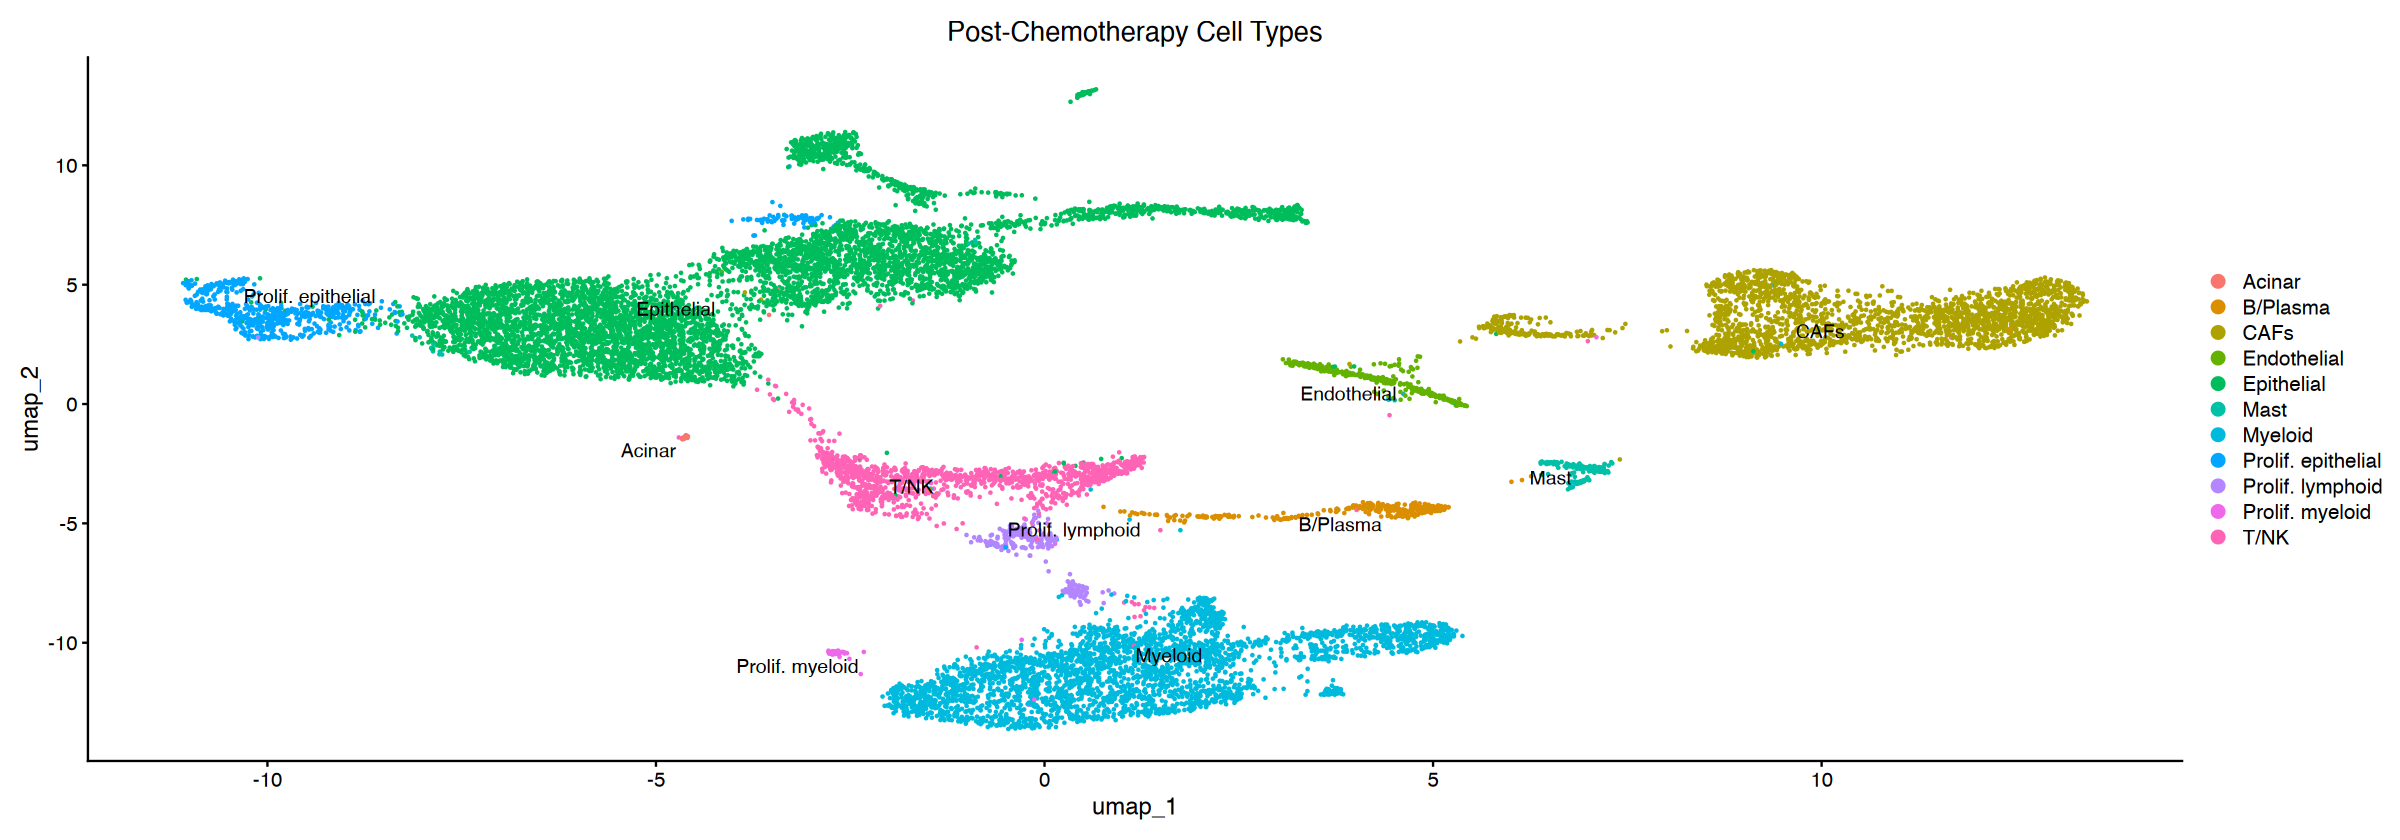

In [20]:
DimPlot(
  postchemo,
  reduction = "umap",
  group.by = "cell_type_refined",
  label = TRUE,
  repel = TRUE
) + ggtitle("Post-Chemotherapy Cell Types")

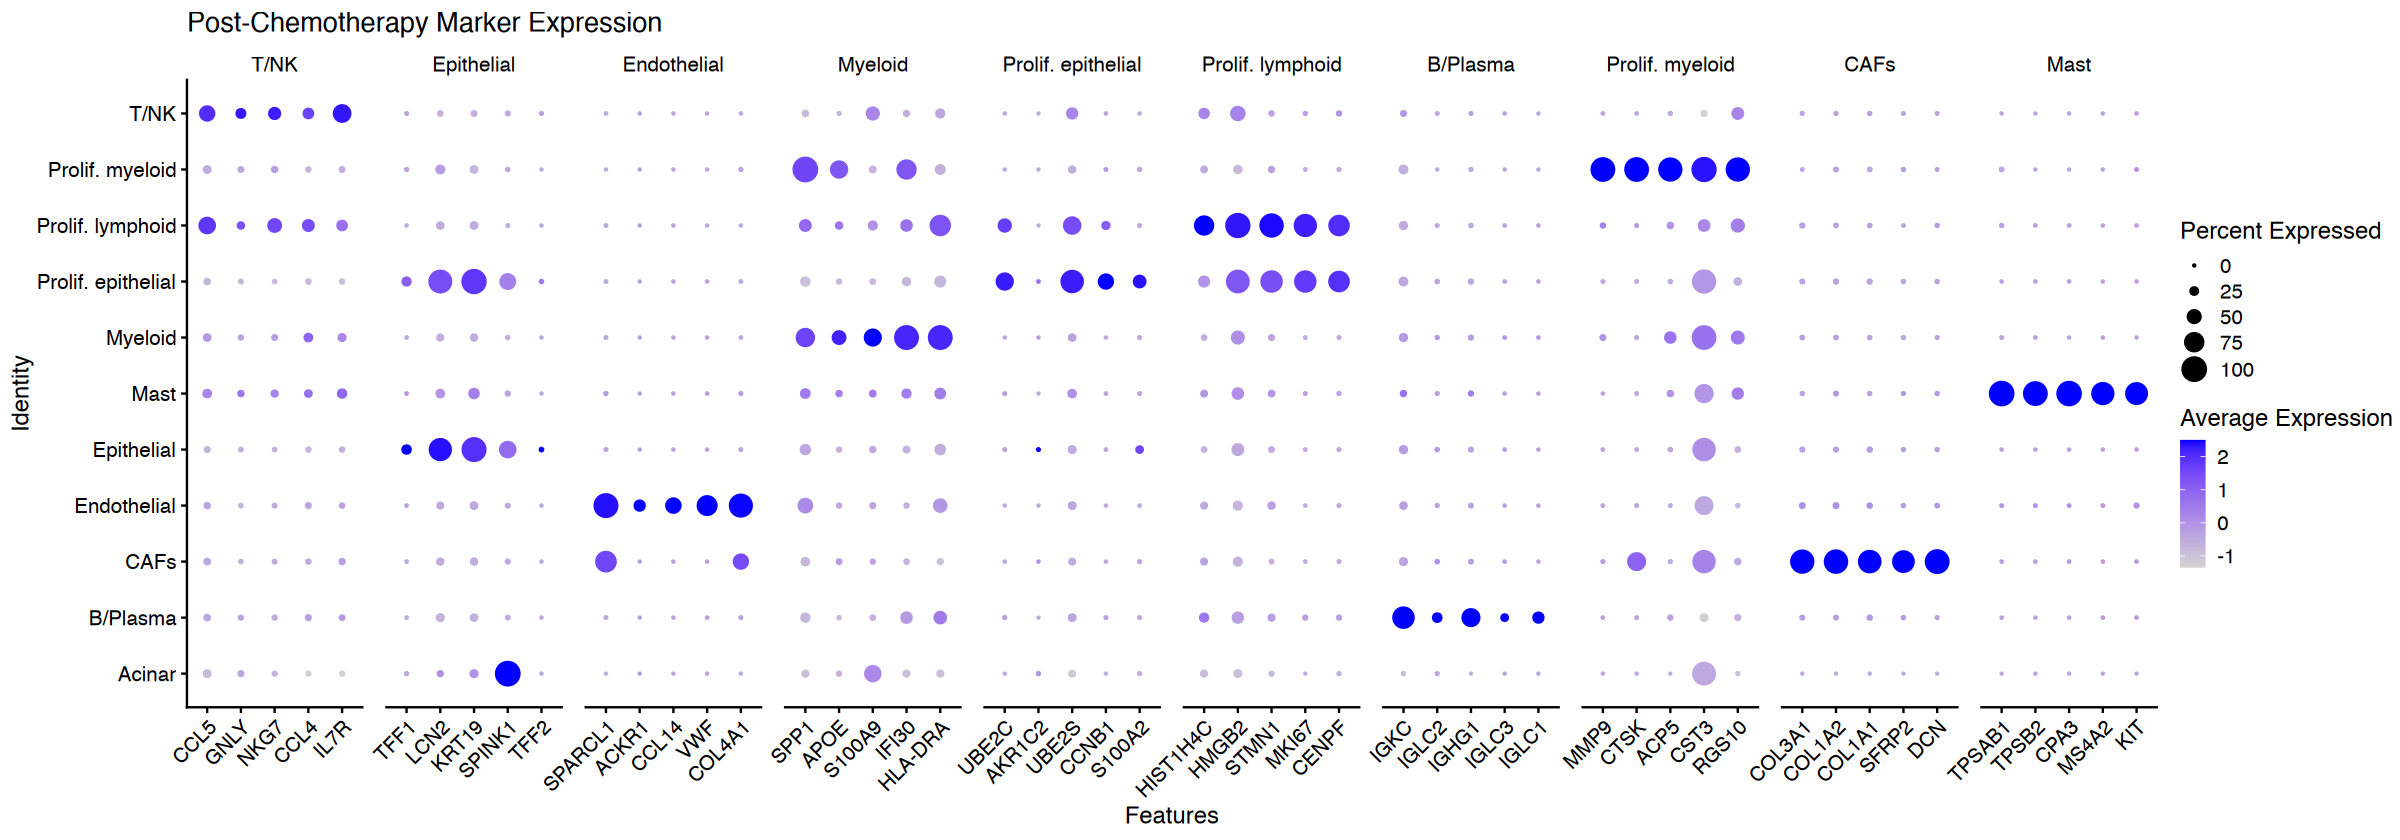

In [21]:
DefaultAssay(postchemo) <- "RNA"

DotPlot(
  postchemo,
  features = cell_type_markers,
  group.by = "cell_type_refined"
) + RotatedAxis() +
  ggtitle("Post-Chemotherapy Marker Expression")